# RAPID response-prediction investigation

This notebook evaluates continuous prediction of the signed RAPID timing response from geometry. It uses grouped leave-one-example-out validation and never uses the timing response as an input feature.

In [11]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'RAPID').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
OUTPUT_ROOT = Path('/Volumes/PhD/river_hierarchy/network_variants/output')
EXAMPLE_IDS = ['02', '03', '05', '11','13','15', '21', '56']  # edit when more real-network outputs are available
RUN_DIR = REPO_ROOT / 'RAPID' / 'classification' / 'results' / f"prediction-notebook-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"


In [12]:
command = [sys.executable, str(REPO_ROOT / 'RAPID/classification/train_rapid_response_regressor.py'),
           '--output-root', str(OUTPUT_ROOT), '--results-dir', str(RUN_DIR),
           '--example-ids', *EXAMPLE_IDS]
subprocess.run(command, cwd=REPO_ROOT, check=True)


Wrote /Users/6256481/Code/river-hierarchy/RAPID/classification/results/prediction-notebook-20260825T133344Z
Recommended regressor: ridge


CompletedProcess(args=['/opt/anaconda3/envs/UNC/bin/python', '/Users/6256481/Code/river-hierarchy/RAPID/classification/train_rapid_response_regressor.py', '--output-root', '/Volumes/PhD/river_hierarchy/network_variants/output', '--results-dir', '/Users/6256481/Code/river-hierarchy/RAPID/classification/results/prediction-notebook-20260825T133344Z', '--example-ids', '02', '03', '05', '11', '13', '15', '21', '56'], returncode=0)

In [13]:
scores = pd.read_csv(RUN_DIR / 'grouped_cv_regression_scores.csv')
predictions = pd.read_csv(RUN_DIR / 'grouped_cv_regression_predictions.csv')
display(scores)


,model,mae_pct_points,rmse_pct_points,r2
0,ridge,0.309965,0.578422,0.254759
1,shallow_tree,0.327677,0.626646,0.125313
2,random_forest,0.332886,0.612498,0.164365
3,extra_trees,0.363109,0.622696,0.136308
4,hist_gradient_boosting,0.390296,0.644658,0.074308
5,mean_response,0.485340,0.740865,-0.222603


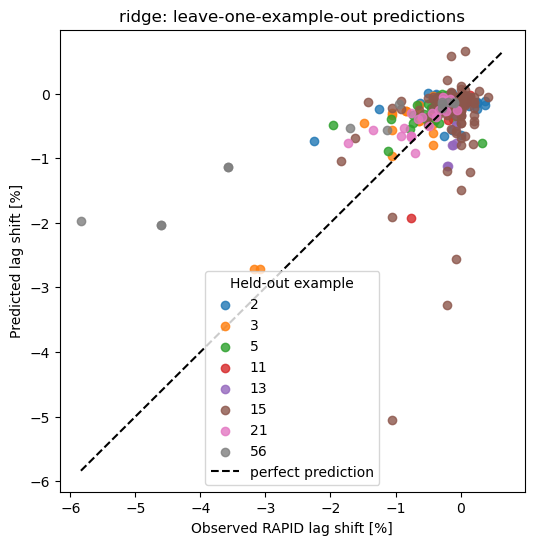

,n,mae,bias
example_id,,,
2,20,0.444969,-0.004433
3,28,0.316299,-0.256842
5,42,0.234128,-0.145572
11,6,0.309994,0.280685
13,28,0.275861,0.275861
15,194,0.262886,0.135515
21,23,0.216515,-0.174022
56,14,1.206046,-1.193034


In [14]:
recommended = scores.iloc[0]['model']
plot_df = predictions.loc[predictions.model.eq(recommended)]
fig, ax = plt.subplots(figsize=(6, 6))
for example_id, group in plot_df.groupby('example_id'):
    ax.scatter(group.observed_lag_shift_pct, group.predicted_lag_shift_pct, label=example_id, alpha=.8)
limits = [min(plot_df.observed_lag_shift_pct.min(), plot_df.predicted_lag_shift_pct.min()),
          max(plot_df.observed_lag_shift_pct.max(), plot_df.predicted_lag_shift_pct.max())]
ax.plot(limits, limits, 'k--', label='perfect prediction')
ax.set(xlabel='Observed RAPID lag shift [%]', ylabel='Predicted lag shift [%]', title=f'{recommended}: leave-one-example-out predictions')
ax.legend(title='Held-out example')
plt.show()
display(plot_df.groupby('example_id').agg(n=('state_id','size'), mae=('residual_pct_points', lambda x: x.abs().mean()), bias=('residual_pct_points','mean')))
